<a href="https://colab.research.google.com/github/nemitha21/S-P500_Stock_Analysis_CWK1/blob/main/S%26P500_Stock_Analysis_CWK1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import io, json, os, platform
from datetime import datetime, timezone

import pandas as pd
import numpy as np
import requests
import yfinance as yf

# Folders (commit these to your public GitHub repo)
os.makedirs("data/raw", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

In [4]:
START = "2021-01-01"
END = "2025-01-01"          # yfinance treats END as EXCLUSIVE, as the brief requires
BENCHMARK = "^GSPC"
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

In [5]:
RETRIEVAL_UTC = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S UTC")

# Wikipedia can reject the default pandas user agent, so fetch the page first
html = requests.get(WIKI_URL, headers={"User-Agent": "Mozilla/5.0 (coursework; student)"}, timeout=30).text
tables = pd.read_html(io.StringIO(html))
constituents = tables[0].copy()          # first table = current constituents

constituents = constituents.rename(columns={
    "Symbol": "wiki_symbol",
    "Security": "company",
    "GICS Sector": "sector",
    "GICS Sub-Industry": "sub_industry",
    "Date added": "date_added",
})
# Yahoo uses "-" where Wikipedia uses "." (e.g. BRK.B -> BRK-B)
constituents["ticker"] = constituents["wiki_symbol"].str.replace(".", "-", regex=False)
constituents["retrieved_utc"] = RETRIEVAL_UTC

print("Retrieved:", RETRIEVAL_UTC)
print("Rows:", len(constituents), "| unique tickers:", constituents["ticker"].nunique())
print(constituents["sector"].value_counts())

constituents.to_csv("data/raw/sp500_constituents_wikipedia.csv", index=False)

Retrieved: 2026-11-19 13:38:13 UTC
Rows: 503 | unique tickers: 503
sector
Industrials               83
Information Technology    76
Financials                76
Health Care               60
Consumer Discretionary    47
Consumer Staples          33
Utilities                 31
Real Estate               30
Materials                 24
Communication Services    22
Energy                    21
Name: count, dtype: int64


In [6]:
tickers = sorted(constituents["ticker"].unique().tolist())

# auto_adjust=False keeps BOTH Close and Adj Close (needed: adjusted for returns, Close for Monetary)
# actions=True adds Dividends and Stock Splits columns (needed for the corporate action checks in 1.2)
def download(tkrs):
    return yf.download(
        tkrs, start=START, end=END, interval="1d",
        auto_adjust=False, actions=True,
        group_by="column", threads=True, progress=False,
    )

raw = download(tickers + [BENCHMARK])
print(raw.shape)
print(raw.columns.get_level_values(0).unique().tolist())

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['Q', 'VYLR', 'SNDK', 'HONA', 'FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


(1005, 4022)
['Adj Close', 'Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']


In [7]:
fields = ["Open", "High", "Low", "Close", "Adj Close", "Volume", "Dividends", "Stock Splits"]

def failed_list(df, tkrs):
    ok = df["Adj Close"].notna().any()
    return [t for t in tkrs if (t not in ok.index) or (not ok[t])]

failed = failed_list(raw, tickers + [BENCHMARK])
print("Failed first pass:", failed)

retry_log = []
for t in failed:
    try:
        d = download([t])
        if "Adj Close" in d.columns.get_level_values(0) and d["Adj Close"].notna().any().any():
            for f in fields:
                if f in d.columns.get_level_values(0):
                    raw[(f, t)] = d[f][t] if isinstance(d[f], pd.DataFrame) else d[f]
            retry_log.append((t, "recovered"))
        else:
            retry_log.append((t, "no data"))
    except Exception as e:
        retry_log.append((t, f"error: {e}"))

raw = raw.sort_index(axis=1)
still_failed = failed_list(raw, tickers + [BENCHMARK])
print("Retry log:", retry_log)
print("Still failed after retry:", still_failed)


Failed first pass: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERRO

Retry log: [('FDXF', 'no data'), ('HONA', 'no data'), ('Q', 'no data'), ('SNDK', 'no data'), ('VYLR', 'no data')]
Still failed after retry: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


In [8]:
for f in fields:
    if f in raw.columns.get_level_values(0):
        raw[f].to_csv(f"data/raw/{f.replace(' ', '_').lower()}.csv")

# Benchmark on its own, for clarity
bench = pd.DataFrame({f: raw[f][BENCHMARK] for f in ["Close", "Adj Close", "Volume"]})
bench.to_csv("data/raw/gspc_benchmark.csv")

# Download log (feeds your inclusion/exclusion log in 1.2)
download_log = pd.DataFrame({
    "ticker": tickers + [BENCHMARK],
    "downloaded": [t not in still_failed for t in tickers + [BENCHMARK]],
})
download_log.to_csv("outputs/download_log.csv", index=False)

In [9]:
meta = {
    "wikipedia_url": WIKI_URL,
    "retrieval_utc": RETRIEVAL_UTC,
    "data_source": "yfinance (Yahoo Finance), auto_adjust=False, actions=True",
    "start_inclusive": START,
    "end_exclusive": END,
    "benchmark": BENCHMARK,
    "n_tickers_requested": len(tickers),
    "n_tickers_failed": len(still_failed),
    "failed_tickers": still_failed,
    "first_date_in_data": str(raw.index.min().date()),
    "last_date_in_data": str(raw.index.max().date()),
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "yfinance": yf.__version__,
}
with open("data/raw/acquisition_metadata.json", "w") as fh:
    json.dump(meta, fh, indent=2)
print(json.dumps(meta, indent=2))

{
  "wikipedia_url": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
  "retrieval_utc": "2026-11-19 13:38:13 UTC",
  "data_source": "yfinance (Yahoo Finance), auto_adjust=False, actions=True",
  "start_inclusive": "2021-01-01",
  "end_exclusive": "2025-01-01",
  "benchmark": "^GSPC",
  "n_tickers_requested": 503,
  "n_tickers_failed": 5,
  "failed_tickers": [
    "FDXF",
    "HONA",
    "Q",
    "SNDK",
    "VYLR"
  ],
  "first_date_in_data": "2021-01-04",
  "last_date_in_data": "2024-12-31",
  "python": "3.13.18",
  "pandas": "2.2.3",
  "numpy": "2.4.6",
  "yfinance": "0.2.66"
}


In [10]:
print("Date range:", raw.index.min().date(), "to", raw.index.max().date())
print("Trading days:", len(raw))
print("Benchmark rows with Adj Close:", raw["Adj Close"][BENCHMARK].notna().sum())
print("Tickers with data:", raw["Adj Close"].notna().any().sum() - 1, "(excluding benchmark)")

Date range: 2021-01-04 to 2024-12-31
Trading days: 1005
Benchmark rows with Adj Close: 1005
Tickers with data: 498 (excluding benchmark)


In [11]:
#1.2 Validation
import json, os
import numpy as np
import pandas as pd

os.makedirs("data/clean", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

BENCH = "^GSPC"

def load(name):
    return pd.read_csv(f"data/raw/{name}.csv", index_col=0, parse_dates=True)

adj, close, vol = load("adj_close"), load("close"), load("volume")
div, spl = load("dividends"), load("stock_splits")
cons = pd.read_csv("data/raw/sp500_constituents_wikipedia.csv")
meta = json.load(open("data/raw/acquisition_metadata.json"))

In [12]:
failed = meta["failed_tickers"]
print(cons.loc[cons.ticker.isin(failed), ["ticker", "company", "sector", "date_added"]])

    ticker              company                  sector  date_added
192   FDXF        FedEx Freight             Industrials  2026-06-01
233   HONA  Honeywell Aerospace             Industrials  2026-06-29
379      Q    Qnity Electronics  Information Technology  2025-11-03
402   SNDK              Sandisk  Information Technology  2025-11-28
478   VYLR                Vylor        Consumer Staples  2026-10-01


In [13]:
print("Duplicate dates:", int(adj.index.duplicated().sum()))
print("Index sorted:", adj.index.is_monotonic_increasing)
print("All price/volume tables share the same dates:",
      all(adj.index.equals(x.index) for x in (close, vol, div, spl)))

ref_dates = adj.index[adj[BENCH].notna()]          # benchmark trading calendar
N_REF, REF_FIRST, REF_LAST = len(ref_dates), ref_dates.min(), ref_dates.max()
print("Benchmark trading days:", N_REF, "|", REF_FIRST.date(), "to", REF_LAST.date())

Duplicate dates: 0
Index sorted: True
All price/volume tables share the same dates: True
Benchmark trading days: 1005 | 2021-01-04 to 2024-12-31


In [14]:
SPLIT_JUMP = 0.40      # |daily Close return| above this with no recorded split -> review flag
RATIO_TOL = 1e-3       # Adj Close / Close ratio change with no dividend -> review flag

tickers = [t for t in adj.columns if t != BENCH]
rows = []
for t in tickers + [BENCH]:
    a, c, v = adj[t], close[t], vol[t]
    valid = a.dropna()
    r = {"ticker": t, "n_valid_adj": len(valid)}
    if len(valid) == 0:
        rows.append(r); continue

    first, last = valid.index.min(), valid.index.max()
    win = slice(first, last)
    r.update({
        "first_date": first, "last_date": last,
        "n_missing_vs_calendar": N_REF - len(valid),
        # missing values INSIDE the share's own history (gaps), across all three fields
        "internal_missing": int(pd.concat([a.loc[win], c.loc[win], v.loc[win]], axis=1).isna().any(axis=1).sum()),
        "nonpositive_price": int((a <= 0).sum() + (c <= 0).sum()),
        "negative_volume": int((v < 0).sum()),
        "zero_volume_days": int((v == 0).sum()),
        "n_splits": int((spl[t].fillna(0) > 0).sum()),
        "n_dividends": int((div[t].fillna(0) > 0).sum()),
    })

    # --- corporate action checks ---
    ret = c.pct_change(fill_method=None)
    r["unexplained_big_jumps"] = int(((ret.abs() > SPLIT_JUMP) & (spl[t].fillna(0) == 0)).sum())

    ratio = a / c
    rchg = ratio.pct_change(fill_method=None).abs()
    r["unexplained_adj_ratio_changes"] = int(((rchg > RATIO_TOL) & (div[t].fillna(0) == 0) & (spl[t].fillna(0) == 0)).sum())

    # traded value (Close x Volume) before vs after each split: ratio near 1 = price and volume on a compatible basis
    tv = c * v
    sp_dates = spl.index[spl[t].fillna(0) > 0]
    tv_ratios = []
    for d in sp_dates:
        i = tv.index.get_loc(d)
        before, after = tv.iloc[max(i - 5, 0):i].mean(), tv.iloc[i:i + 5].mean()
        tv_ratios.append(round(after / before, 2) if before and before > 0 else np.nan)
    r["split_dates"] = ";".join(str(d.date()) for d in sp_dates)
    r["split_traded_value_ratio"] = ";".join(map(str, tv_ratios))
    rows.append(r)

summary = pd.DataFrame(rows).set_index("ticker")
summary.to_csv("outputs/validation_summary.csv")
print("Benchmark row:\n", summary.loc[BENCH].to_string())

Benchmark row:
 n_valid_adj                                     1005
first_date                       2021-01-04 00:00:00
last_date                        2024-12-31 00:00:00
n_missing_vs_calendar                            0.0
internal_missing                                 0.0
nonpositive_price                                0.0
negative_volume                                  0.0
zero_volume_days                                 1.0
n_splits                                         0.0
n_dividends                                      0.0
unexplained_big_jumps                            0.0
unexplained_adj_ratio_changes                    0.0
split_dates                                         
split_traded_value_ratio                            


In [15]:
s = summary.drop(index=BENCH)
cov = s["n_valid_adj"].fillna(0) / N_REF
print("Shares with 100% coverage     :", int((cov == 1).sum()))
print("Shares with >=99% coverage    :", int((cov >= 0.99).sum()))
print("Shares with >=95% coverage    :", int((cov >= 0.95).sum()))
print("Shares with >=90% coverage    :", int((cov >= 0.90).sum()))
print("\nMissing-day distribution (among shares with data):")
print(s["n_missing_vs_calendar"].describe())
print("\nLate listings (first date after benchmark start):")
late = s[s["first_date"] > REF_FIRST]
print(late[["first_date", "n_valid_adj"]].sort_values("first_date").to_string())


Shares with 100% coverage     : 488
Shares with >=99% coverage    : 488
Shares with >=95% coverage    : 489
Shares with >=90% coverage    : 491

Missing-day distribution (among shares with data):
count    498.000000
mean       8.405622
std       74.461529
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max      812.000000
Name: n_missing_vs_calendar, dtype: float64

Late listings (first date after benchmark start):
       first_date  n_valid_adj
ticker                        
EXE    2021-02-10          979
COIN   2021-04-14          936
APP    2021-04-15          935
HOOD   2021-07-29          862
CEG    2022-01-19          742
GEHC   2022-12-15          513
VLTO   2023-10-04          313
RDDT   2024-03-21          197
SOLV   2024-03-26          194
GEV    2024-03-27          193


In [16]:
def reasons(r):
    out = []
    if r["n_valid_adj"] == 0 or pd.isna(r.get("first_date")):
        return ["no_price_data"]
    if r["first_date"] > REF_FIRST or r["last_date"] < REF_LAST:
        out.append("unequal_history")
    if r["internal_missing"] > 0:
        out.append("missing_values")
    if r["nonpositive_price"] > 0:
        out.append("nonpositive_price")
    if r["negative_volume"] > 0:
        out.append("negative_volume")
    if r["zero_volume_days"] > 0:
        out.append("zero_volume_days")
    return out

s = s.copy()
s["exclusion_reasons"] = s.apply(reasons, axis=1)
s["included"] = s["exclusion_reasons"].apply(len) == 0

excl = s.loc[~s["included"], ["exclusion_reasons"]].copy()
excl["exclusion_reasons"] = excl["exclusion_reasons"].apply(";".join)
excl = excl.join(cons.set_index("ticker")[["company", "sector"]])
excl.to_csv("outputs/exclusion_log.csv")

included = s.index[s["included"]].tolist()
pd.Series(included, name="ticker").to_csv("outputs/included_tickers.csv", index=False)

print("Included:", len(included), "| Excluded:", len(excl))
print(excl["exclusion_reasons"].value_counts())

Included: 486 | Excluded: 17
exclusion_reasons
unequal_history     10
no_price_data        5
zero_volume_days     2
Name: count, dtype: int64


In [17]:
flags = s.loc[s["included"] & (
    (s["unexplained_big_jumps"] > 0) | (s["unexplained_adj_ratio_changes"] > 0)
), ["unexplained_big_jumps", "unexplained_adj_ratio_changes", "n_splits", "split_dates"]]
flags.to_csv("outputs/review_flags.csv")
print("Included shares with review flags:", len(flags))
print(flags.head(20).to_string())

print("\nSplit traded-value check (ratio should be near 1):")
chk = s.loc[s["included"] & (s["n_splits"] > 0), ["split_dates", "split_traded_value_ratio"]]
print(chk.to_string())

Included shares with review flags: 4
        unexplained_big_jumps  unexplained_adj_ratio_changes  n_splits split_dates
ticker                                                                            
BE                        1.0                            0.0       0.0            
CVNA                      5.0                            0.0       0.0            
DXCM                      1.0                            0.0       1.0  2022-06-13
GL                        1.0                            0.0       0.0            

Split traded-value check (ratio should be near 1):
                             split_dates split_traded_value_ratio
ticker                                                           
AMZN                          2022-06-06                     0.77
ANET               2021-11-18;2024-12-04                1.09;1.08
APH                2021-03-05;2024-06-12                0.93;1.01
AVGO                          2024-07-15                     0.73
BDX              

In [18]:
keep = included + [BENCH]
for name, df in [("adj_close", adj), ("close", close), ("volume", vol), ("dividends", div), ("stock_splits", spl)]:
    df[keep].to_csv(f"data/clean/{name}_valid.csv")

before = cons["sector"].value_counts()
after = cons.set_index("ticker").loc[included, "sector"].value_counts()
print(pd.concat([before.rename("all_503"), after.rename("included")], axis=1).fillna(0).astype(int))

print("\nBenchmark and included shares are on the same", N_REF, "daily dates.")
print("Any NaN left in the clean adjusted close?", bool(adj[keep].isna().any().any()))

                        all_503  included
sector                                   
Industrials                  83        78
Information Technology       76        74
Financials                   76        74
Health Care                  60        58
Consumer Discretionary       47        47
Consumer Staples             33        32
Utilities                    31        30
Real Estate                  30        30
Materials                    24        23
Communication Services       22        20
Energy                       21        20

Benchmark and included shares are on the same 1005 daily dates.
Any NaN left in the clean adjusted close? False


In [19]:
#weekly returns
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("data/clean", exist_ok=True)

BENCH = "^GSPC"
START, END = "2021-01-01", "2025-01-01"      # END is exclusive

def load_clean(name):
    return pd.read_csv(f"data/clean/{name}_valid.csv", index_col=0, parse_dates=True)

adj = load_clean("adj_close")
close = load_clean("close")
included = pd.read_csv("outputs/included_tickers.csv")["ticker"].tolist()
cons = pd.read_csv("data/raw/sp500_constituents_wikipedia.csv").set_index("ticker")

assert adj.isna().sum().sum() == 0, "Unexpected NaN in clean adjusted close"
print("Included shares:", len(included), "| daily rows:", len(adj))

Included shares: 486 | daily rows: 1005


In [20]:
diff = (adj[BENCH] - close[BENCH]).abs().max()
print("Max |Adj Close - Close| for ^GSPC:", diff)

Max |Adj Close - Close| for ^GSPC: 0.0


In [21]:
adj_w_all = adj.resample("W-FRI").last()

cal = pd.Series(adj.index, index=adj.index)
wk = pd.DataFrame({
    "last_trading_date": cal.resample("W-FRI").last(),
    "n_trading_days": cal.resample("W-FRI").count(),
})
wk["week_start_monday"] = wk.index - pd.Timedelta(days=4)

# A week is kept only if its whole Monday-Friday span lies inside the study window.
# This drops the incomplete final week (Dec 30 2024 - Jan 3 2025, only Dec 30-31 in the data)
# and keeps normal holiday-shortened weeks.
wk["complete_in_window"] = (
    (wk["week_start_monday"] >= pd.Timestamp(START))
    & (wk.index <= pd.Timestamp(END) - pd.Timedelta(days=1))
)

print("Weeks with zero trading days (should be 0):", int((wk["n_trading_days"] == 0).sum()))
print("\nFirst weeks:\n", wk.head(3))
print("\nLast weeks:\n", wk.tail(3))
print("\nTrading days per week:\n", wk["n_trading_days"].value_counts().sort_index())
print("\nDropped weeks:\n", wk.loc[~wk["complete_in_window"]])

adj_w = adj_w_all.loc[wk.index[wk["complete_in_window"]]]
adj_w.to_csv("data/clean/weekly_adj_close.csv")
wk.to_csv("outputs/weekly_calendar_log.csv")

Weeks with zero trading days (should be 0): 0

First weeks:
            last_trading_date  n_trading_days week_start_monday  \
Date                                                             
2021-01-08        2021-01-08               5        2021-01-04   
2021-01-15        2021-01-15               5        2021-01-11   
2021-01-22        2021-01-22               4        2021-01-18   

            complete_in_window  
Date                            
2021-01-08                True  
2021-01-15                True  
2021-01-22                True  

Last weeks:
            last_trading_date  n_trading_days week_start_monday  \
Date                                                             
2024-12-20        2024-12-20               5        2024-12-16   
2024-12-27        2024-12-27               4        2024-12-23   
2025-01-03        2024-12-31               2        2024-12-30   

            complete_in_window  
Date                            
2024-12-20                True  

In [22]:
ret_w = adj_w.pct_change(fill_method=None).iloc[1:]      # first week has no preceding week
ret_w.to_csv("data/clean/weekly_returns.csv")

print("Weekly price points:", len(adj_w), "| weekly returns (observations):", len(ret_w))
print("Return window:", ret_w.index.min().date(), "to", ret_w.index.max().date())
print("NaN in weekly returns:", int(ret_w.isna().sum().sum()))
assert ret_w.index.equals(ret_w[BENCH].dropna().index)   # benchmark and shares share identical week labels

# extreme weeks worth a look (not removed)
big = (ret_w[included].abs() > 0.5).sum()
print("\nShares with any |weekly return| > 50%:\n", big[big > 0].sort_values(ascending=False))

Weekly price points: 208 | weekly returns (observations): 207
Return window: 2021-01-15 to 2024-12-27
NaN in weekly returns: 0

Shares with any |weekly return| > 50%:
 CVNA    3
BE      2
SKYD    1
SMCI    1
dtype: int64


In [23]:
r_b = ret_w[BENCH]
r_s = ret_w[included]

mean_ret = r_s.mean()                                   # arithmetic mean
beta = r_s.apply(lambda s: s.cov(r_b)) / r_b.var()      # cov(share, benchmark) / var(benchmark); both ddof=1

# independent check: OLS slope of share return on benchmark return must equal beta
beta_check = pd.Series({t: np.polyfit(r_b.values, r_s[t].values, 1)[0] for t in included})
print("Max |beta - OLS slope|:", float((beta - beta_check).abs().max()))
print("Benchmark beta against itself (must be 1):", r_b.cov(r_b) / r_b.var())

feat = pd.DataFrame({
    "mean_weekly_return": mean_ret,
    "weekly_beta": beta,
    "n_weekly_obs": r_s.count(),
}).join(cons[["company", "sector"]])
feat.to_csv("outputs/feature_table_risk_return.csv")

print("\nObservation counts (all must be equal):", feat["n_weekly_obs"].unique())
print(feat[["mean_weekly_return", "weekly_beta"]].describe())

Max |beta - OLS slope|: 2.220446049250313e-15
Benchmark beta against itself (must be 1): 1.0

Observation counts (all must be equal): [207]
       mean_weekly_return  weekly_beta
count          486.000000   486.000000
mean             0.002857     0.973695
std              0.002652     0.407339
min             -0.004468     0.055454
25%              0.001182     0.666599
50%              0.002619     0.950609
75%              0.004207     1.179538
max              0.017772     3.778560


In [24]:
ex = "AAPL" if "AAPL" in included else included[0]
tab = pd.DataFrame({"adj_close_week_end": adj_w[ex], "benchmark_adj_close": adj_w[BENCH]})
tab["share_return"] = tab["adj_close_week_end"].pct_change(fill_method=None)
tab["bench_return"] = tab["benchmark_adj_close"].pct_change(fill_method=None)
print(tab.head(5))

x, y = tab["bench_return"].dropna(), tab["share_return"].dropna()
manual = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()   # cov/var with matching denominators
print(f"\n{ex}: mean weekly return = {y.mean():.5f} | beta (manual) = {manual:.4f} | beta (table) = {beta[ex]:.4f}")

            adj_close_week_end  benchmark_adj_close  share_return  \
Date                                                                
2021-01-08          128.098129          3824.679932           NaN   
2021-01-15          123.335045          3768.250000     -0.037183   
2021-01-22          134.908020          3841.469971      0.093834   
2021-01-29          128.010818          3714.239990     -0.051125   
2021-02-05          132.865387          3886.830078      0.037923   

            bench_return  
Date                      
2021-01-08           NaN  
2021-01-15     -0.014754  
2021-01-22      0.019431  
2021-01-29     -0.033120  
2021-02-05      0.046467  

AAPL: mean weekly return = 0.00393 | beta (manual) = 1.1748 | beta (table) = 1.1748


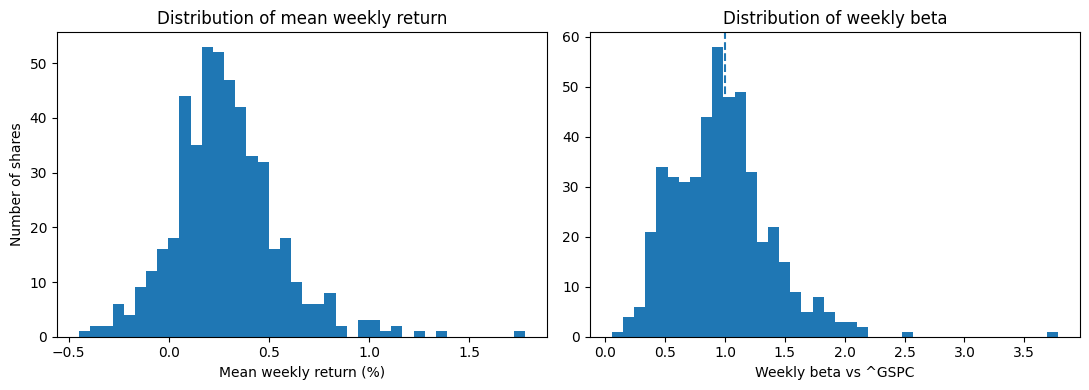

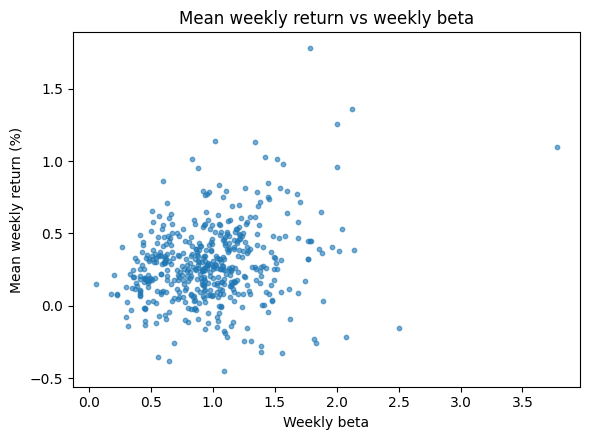

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(feat["mean_weekly_return"] * 100, bins=40)
ax[0].set_xlabel("Mean weekly return (%)"); ax[0].set_ylabel("Number of shares")
ax[0].set_title("Distribution of mean weekly return")
ax[1].hist(feat["weekly_beta"], bins=40)
ax[1].axvline(1, linestyle="--")
ax[1].set_xlabel("Weekly beta vs ^GSPC"); ax[1].set_title("Distribution of weekly beta")
plt.tight_layout()
plt.savefig("outputs/figures/fig_return_beta_distributions.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(feat["weekly_beta"], feat["mean_weekly_return"] * 100, s=10, alpha=0.6)
ax.set_xlabel("Weekly beta"); ax.set_ylabel("Mean weekly return (%)")
ax.set_title("Mean weekly return vs weekly beta")
plt.tight_layout()
plt.savefig("outputs/figures/fig_return_vs_beta.png", dpi=200)
plt.show()

In [26]:
#1.4 Adapted RFM calculations

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("outputs/figures", exist_ok=True)

def load_clean(name):
    return pd.read_csv(f"data/clean/{name}_valid.csv", index_col=0, parse_dates=True)

included = pd.read_csv("outputs/included_tickers.csv")["ticker"].tolist()
close = load_clean("close")[included]
vol = load_clean("volume")[included]

assert not close.isna().any().any() and not vol.isna().any().any(), "NaN found: re-check Step 2"
print("Shares:", len(included), "| sessions:", len(vol))

Shares: 486 | sessions: 1005


In [27]:
BASELINE = 20      # preceding sessions used for the volume baseline (current day excluded)
WINDOW = 60        # latest sessions used for Frequency and Monetary
MULT = 2.0         # event if volume > MULT x baseline mean

obs_date = vol.index.max()                    # final common completed trading date in the study period
assert vol.loc[obs_date].notna().all()
last60 = vol.index[-WINDOW:]

print("Observation date:", obs_date.date())
print("60-session window:", last60[0].date(), "to", last60[-1].date())
print("First date an event can be tested (needs 20 prior sessions):", vol.index[BASELINE].date())
print("Sessions before the 60-session window:", len(vol) - WINDOW, "(must be >= 20)")

Observation date: 2024-12-31
60-session window: 2024-10-07 to 2024-12-31
First date an event can be tested (needs 20 prior sessions): 2021-02-02
Sessions before the 60-session window: 945 (must be >= 20)


In [28]:
baseline_mean = vol.shift(1).rolling(BASELINE, min_periods=BASELINE).mean()
threshold = MULT * baseline_mean
event = vol > threshold                      # NaN threshold (first 20 sessions) gives False

event.to_csv("data/clean/high_volume_flags.csv")      # preserved, reproducible event flags
print("Total event flags:", int(event.sum().sum()))
print("Events per share (summary):")
print(event.sum().describe())

Total event flags: 18280
Events per share (summary):
count    486.000000
mean      37.613169
std        9.552813
min       15.000000
25%       31.000000
50%       37.000000
75%       44.000000
max       75.000000
dtype: float64


In [29]:
# %% Cell 4: R, F, M
last_event = pd.to_datetime(event.apply(lambda s: s.index[s].max() if s.any() else pd.NaT))
R = (obs_date - last_event).dt.days           # calendar days (weekends and holidays included); event on obs date gives 0
F = event.loc[last60].sum()                   # event days in the latest 60 sessions
M = (close * vol).loc[last60].sum()           # approximate traded value in USD

rfm = pd.DataFrame({
    "R": R, "F": F, "M": M,
    "last_event_date": last_event,
    "n_events_total": event.sum(),
})
rfm["rfm_valid"] = rfm["R"].notna()

print("Shares with NO event in valid history (R missing, excluded from RFM clustering):",
      int((~rfm["rfm_valid"]).sum()), rfm.index[~rfm["rfm_valid"]].tolist())
print("Shares with an event on the observation date (R = 0):", int((rfm["R"] == 0).sum()))
print("Shares with F = 0:", int((rfm["F"] == 0).sum()))

Shares with NO event in valid history (R missing, excluded from RFM clustering): 0 []
Shares with an event on the observation date (R = 0): 0
Shares with F = 0: 10


In [30]:
def slow(t):
    v, c, d = vol[t].values, close[t].values, vol.index
    ev = [i for i in range(BASELINE, len(v)) if v[i] > MULT * v[i - BASELINE:i].mean()]
    r_ = (obs_date - d[ev[-1]]).days if ev else np.nan
    f_ = sum(1 for i in ev if i >= len(v) - WINDOW)
    m_ = float((c[-WINDOW:] * v[-WINDOW:]).sum())
    return r_, f_, m_

chk = pd.DataFrame({t: slow(t) for t in included}, index=["R", "F", "M"]).T
print("R matches:", np.allclose(chk["R"].fillna(-1), rfm["R"].fillna(-1)))
print("F matches:", (chk["F"] == rfm["F"]).all())
print("M matches:", np.allclose(chk["M"], rfm["M"]))

R matches: True
F matches: True
M matches: True


In [31]:
def flag(v):
    s = pd.Series(v, dtype=float)
    return s > MULT * s.shift(1).rolling(BASELINE, min_periods=BASELINE).mean()

base = [1_000_000] * 20
assert flag(base + [2_500_000]).iloc[-1]            # brief example: qualifies
assert not flag(base + [1_800_000]).iloc[-1]        # brief example: does not qualify
assert not flag(base + [2_000_000]).iloc[-1]        # exactly 2x is NOT greater than 2x
assert not flag([1_000_000] * 19 + [9_000_000]).iloc[-1]   # only 19 prior sessions: not testable
# a spike raises the baseline of LATER days only (day tested is excluded from its own baseline):
# after a 5M spike the next baseline is (19 x 1M + 5M)/20 = 1.2M, so threshold = 2.4M
assert flag(base + [5_000_000, 2_500_000]).iloc[-1]
assert not flag(base + [5_000_000, 2_300_000]).iloc[-1]
print("All boundary tests passed")

All boundary tests passed


In [32]:
ex = "AAPL" if "AAPL" in included else included[0]
d = pd.DataFrame({
    "close": close[ex], "volume": vol[ex],
    "baseline_mean_20": baseline_mean[ex], "threshold_2x": threshold[ex], "event": event[ex],
})
d["traded_value_usd"] = d["close"] * d["volume"]

print(f"--- {ex}: event days inside the 60-session window ---")
print(d.loc[last60].query("event").round(2))
print("\nLatest event in whole history:", rfm.loc[ex, "last_event_date"].date())
print(f"R = {obs_date.date()} - {rfm.loc[ex, 'last_event_date'].date()} = {rfm.loc[ex, 'R']:.0f} calendar days")
print(f"F = {rfm.loc[ex, 'F']:.0f} | M = ${rfm.loc[ex, 'M']:,.0f}")
print("Manual M:", f"${d.loc[last60, 'traded_value_usd'].sum():,.0f}")

--- AAPL: event days inside the 60-session window ---
             close     volume  baseline_mean_20  threshold_2x  event  \
Date                                                                   
2024-11-25  232.87   90152800        43820740.0    87641480.0   True   
2024-12-20  254.49  147495300        45004605.0    90009210.0   True   

            traded_value_usd  
Date                          
2024-11-25      2.099388e+10  
2024-12-20      3.753608e+10  

Latest event in whole history: 2024-12-20
R = 2024-12-31 - 2024-12-20 = 11 calendar days
F = 2 | M = $623,303,377,707
Manual M: $623,303,377,707


            R       F             M  log1p_M
count  486.00  486.00  4.860000e+02   486.00
mean    20.41    2.99  3.940419e+10    23.68
std     21.34    1.33  1.291388e+11     0.94
min      4.00    0.00  1.297483e+09    20.98
25%     11.00    2.00  1.019517e+10    23.05
50%     11.00    3.00  1.668382e+10    23.54
75%     14.75    4.00  3.227689e+10    24.20
max    222.00    8.00  1.847697e+12    28.24

Skewness:
 R           3.65
F           0.42
M          11.68
log1p_M     1.08
dtype: float64

Most common R values (shares bunching on the same event date?):
R
11    353
36     17
55     11
60      6
46      6
25      5
Name: count, dtype: int64

Dates in the window with the highest share of stocks flagged:
Date
2024-12-20    72.8
2024-11-06    32.1
2024-10-31    17.1
2024-11-25    15.6
2024-10-30     9.5
Name: % of shares flagged, dtype: float64


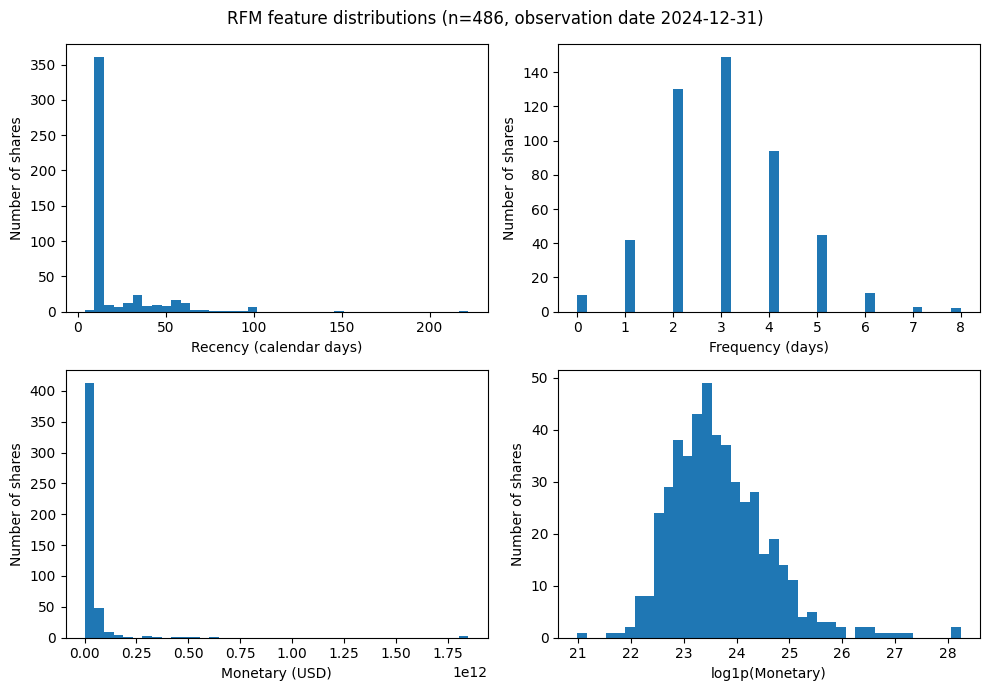

In [33]:
valid = rfm[rfm["rfm_valid"]].copy()
valid["log1p_M"] = np.log1p(valid["M"])

print(valid[["R", "F", "M", "log1p_M"]].describe().round(2))
print("\nSkewness:\n", valid[["R", "F", "M", "log1p_M"]].skew().round(2))

print("\nMost common R values (shares bunching on the same event date?):")
print(valid["R"].value_counts().head(6))

share_with_event = event.loc[last60].mean(axis=1).sort_values(ascending=False)
print("\nDates in the window with the highest share of stocks flagged:")
print((share_with_event.head(5) * 100).round(1).rename("% of shares flagged"))

fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for a, col, lab in zip(ax.ravel(), ["R", "F", "M", "log1p_M"],
                       ["Recency (calendar days)", "Frequency (days)", "Monetary (USD)", "log1p(Monetary)"]):
    a.hist(valid[col], bins=40)
    a.set_xlabel(lab); a.set_ylabel("Number of shares")
fig.suptitle(f"RFM feature distributions (n={len(valid)}, observation date {obs_date.date()})")
plt.tight_layout()
plt.savefig("outputs/figures/fig_rfm_distributions.png", dpi=200)
plt.show()

In [35]:
risk = pd.read_csv("outputs/feature_table_risk_return.csv", index_col=0)
full = risk.join(rfm)
full.to_csv("outputs/feature_table_all.csv")

common = full[full["rfm_valid"]]
common.index.to_series().to_csv("outputs/common_valid_shares.csv", index=False)
print("Shares with risk/return features:", len(full), "| with valid RFM (common set):", len(common))

meta = {
    "observation_date": str(obs_date.date()),
    "window_first_session": str(last60[0].date()),
    "window_sessions": WINDOW, "baseline_sessions": BASELINE, "threshold_multiplier": MULT,
    "event_rule": "volume > 2 x mean volume of preceding 20 sessions (current day excluded), strict inequality",
    "recency_basis": "calendar days to latest event in whole valid history",
    "n_shares_rfm_valid": int(len(common)),
    "calculation_version": "v1",
}
json.dump(meta, open("outputs/rfm_metadata.json", "w"), indent=2)
print(json.dumps(meta, indent=2))

Shares with risk/return features: 486 | with valid RFM (common set): 486
{
  "observation_date": "2024-12-31",
  "window_first_session": "2024-10-07",
  "window_sessions": 60,
  "baseline_sessions": 20,
  "threshold_multiplier": 2.0,
  "event_rule": "volume > 2 x mean volume of preceding 20 sessions (current day excluded), strict inequality",
  "recency_basis": "calendar days to latest event in whole valid history",
  "n_shares_rfm_valid": 486,
  "calculation_version": "v1"
}


In [36]:
#2.1 Feature preparation

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

os.makedirs("outputs/figures", exist_ok=True)

full = pd.read_csv("outputs/feature_table_all.csv", index_col=0)
need = ["mean_weekly_return", "weekly_beta", "R", "F", "M"]

common = full.dropna(subset=need)
common = common[common["rfm_valid"].astype(bool)].copy()
print("Shares with all features (common set):", len(common), "of", len(full))

Shares with all features (common set): 486 of 486


In [37]:
raw = common[need].copy()
raw["log1p_M"] = np.log1p(raw["M"])
raw["log1p_R"] = np.log1p(raw["R"])      # diagnostic only, unless you set LOG_R = True below

def diagnostics(df):
    q1, q3 = df.quantile(0.25), df.quantile(0.75)
    iqr = q3 - q1
    z = (df - df.mean()) / df.std(ddof=0)
    top5_share = (z ** 2).apply(lambda s: s.nlargest(5).sum() / s.sum())   # share of total variance from the 5 most extreme shares
    return pd.DataFrame({
        "mean": df.mean(), "median": df.median(),
        "skew": df.skew(), "excess_kurtosis": df.kurt(),
        "n_outliers_IQR": ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum(),
        "n_abs_z_gt_3": (z.abs() > 3).sum(),
        "max_abs_z": z.abs().max(),
        "top5_share_of_variance": top5_share,
    })

diag = diagnostics(raw)
print(diag.round(3).to_string())
diag.round(4).to_csv("outputs/feature_diagnostics.csv")

                            mean        median    skew  excess_kurtosis  n_outliers_IQR  n_abs_z_gt_3  max_abs_z  top5_share_of_variance
mean_weekly_return  3.000000e-03  3.000000e-03   0.868            3.019              15             6      5.631                   0.169
weekly_beta         9.740000e-01  9.510000e-01   1.104            4.471              10             2      6.893                   0.175
R                   2.040700e+01  1.100000e+01   3.646           21.004             115            11      9.455                   0.352
F                   2.990000e+00  3.000000e+00   0.425            0.545               2             5      3.769                   0.115
M                   3.940419e+10  1.668382e+10  11.684          155.513              45             5     14.017                   0.894
log1p_M             2.368200e+01  2.353800e+01   1.079            2.691              13             7      4.848                   0.174
log1p_R             2.809000e+00  2.48500

In [38]:
for col in ["weekly_beta", "mean_weekly_return", "M", "R"]:
    z = ((common[col] - common[col].mean()) / common[col].std(ddof=0)).abs()
    print(f"\nMost extreme on {col}:")
    print(common.loc[z.nlargest(5).index, ["company", "sector", col]].to_string())

# %% Cell 4: build the two matrices, standardise each separately
LOG_R = False        # set True only if the diagnostics convince you, and justify it in the report

X_rr_raw = common[["mean_weekly_return", "weekly_beta"]].copy()

X_act_raw = pd.DataFrame({"R": common["R"], "F": common["F"], "log1p_M": np.log1p(common["M"])})
if LOG_R:
    X_act_raw["R"] = np.log1p(X_act_raw["R"])
    X_act_raw = X_act_raw.rename(columns={"R": "log1p_R"})

assert X_rr_raw.index.equals(X_act_raw.index)        # identical shares in both matrices
assert not X_rr_raw.isna().any().any() and not X_act_raw.isna().any().any()

sc_rr, sc_act = StandardScaler(), StandardScaler()   # fitted separately, one per matrix
X_rr = pd.DataFrame(sc_rr.fit_transform(X_rr_raw), index=X_rr_raw.index, columns=X_rr_raw.columns)
X_act = pd.DataFrame(sc_act.fit_transform(X_act_raw), index=X_act_raw.index, columns=X_act_raw.columns)

print("Standardised means (should be ~0):\n", X_rr.mean().round(10).to_dict(), X_act.mean().round(10).to_dict())
print("Standardised std (should be 1):\n", X_rr.std(ddof=0).round(6).to_dict(), X_act.std(ddof=0).round(6).to_dict())

common.to_csv("outputs/features_common_set_original_units.csv")
X_rr.to_csv("outputs/X_riskreturn_scaled.csv")
X_act.to_csv("outputs/X_activity_scaled.csv")
X_rr_raw.to_csv("outputs/X_riskreturn_raw.csv")
X_act_raw.to_csv("outputs/X_activity_raw.csv")


Most extreme on weekly_beta:
             company                  sector  weekly_beta
CVNA         Carvana  Consumer Discretionary     3.778560
XYZ      Block, Inc.              Financials     2.504520
COHR  Coherent Corp.  Information Technology     2.139305
NVDA          Nvidia  Information Technology     2.125954
TWLO          Twilio  Information Technology     2.073379

Most extreme on mean_weekly_return:
                  company                  sector  mean_weekly_return
SMCI           Supermicro  Information Technology            0.017772
NVDA               Nvidia  Information Technology            0.013624
VRT                Vertiv             Industrials            0.012583
VST          Vistra Corp.               Utilities            0.011395
FIX   Comfort Systems USA             Industrials            0.011297

Most extreme on M:
          company                  sector             M
TSLA  Tesla, Inc.  Consumer Discretionary  1.847697e+12
NVDA       Nvidia  Information Te

In [39]:
cmp = pd.DataFrame({
    "M raw": diagnostics(raw[["M"]]).iloc[0],
    "log1p(M)": diagnostics(raw[["log1p_M"]]).iloc[0],
    "R raw": diagnostics(raw[["R"]]).iloc[0],
    "log1p(R)": diagnostics(raw[["log1p_R"]]).iloc[0],
}).T[["skew", "n_abs_z_gt_3", "max_abs_z", "top5_share_of_variance"]]
print(cmp.round(3).to_string())
print("\nReading guide: after standardisation every feature has variance 1, but if the top 5 shares hold a large")
print("share of that variance, distances (and so clusters) are being driven by a handful of shares.")

            skew  n_abs_z_gt_3  max_abs_z  top5_share_of_variance
M raw     11.684           5.0     14.017                   0.894
log1p(M)   1.079           7.0      4.848                   0.174
R raw      3.646          11.0      9.455                   0.352
log1p(R)   1.583           2.0      4.216                   0.117

Reading guide: after standardisation every feature has variance 1, but if the top 5 shares hold a large
share of that variance, distances (and so clusters) are being driven by a handful of shares.


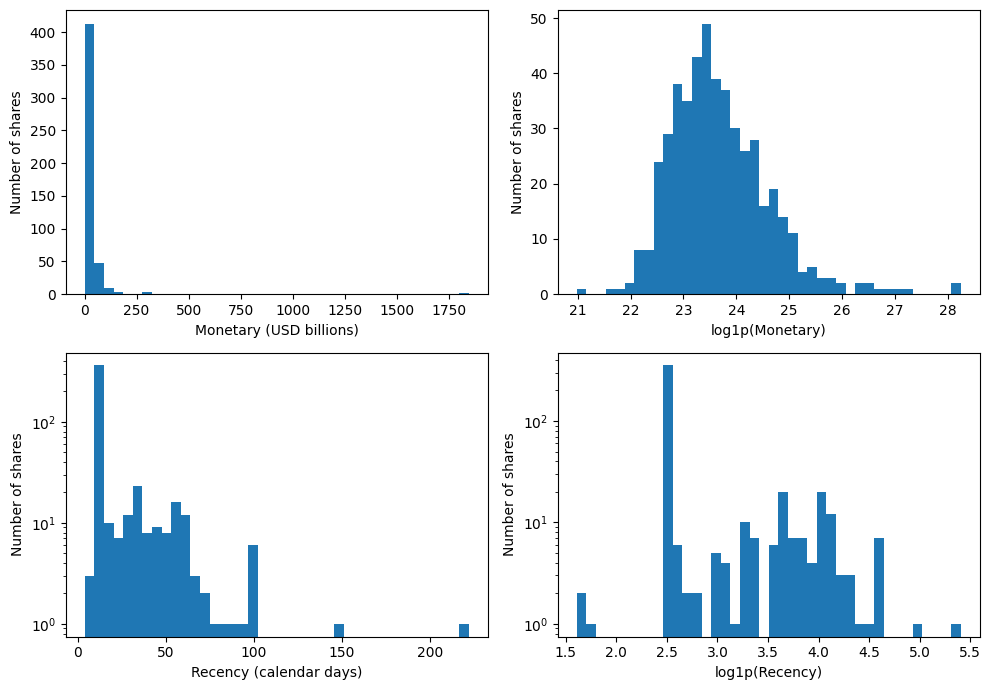

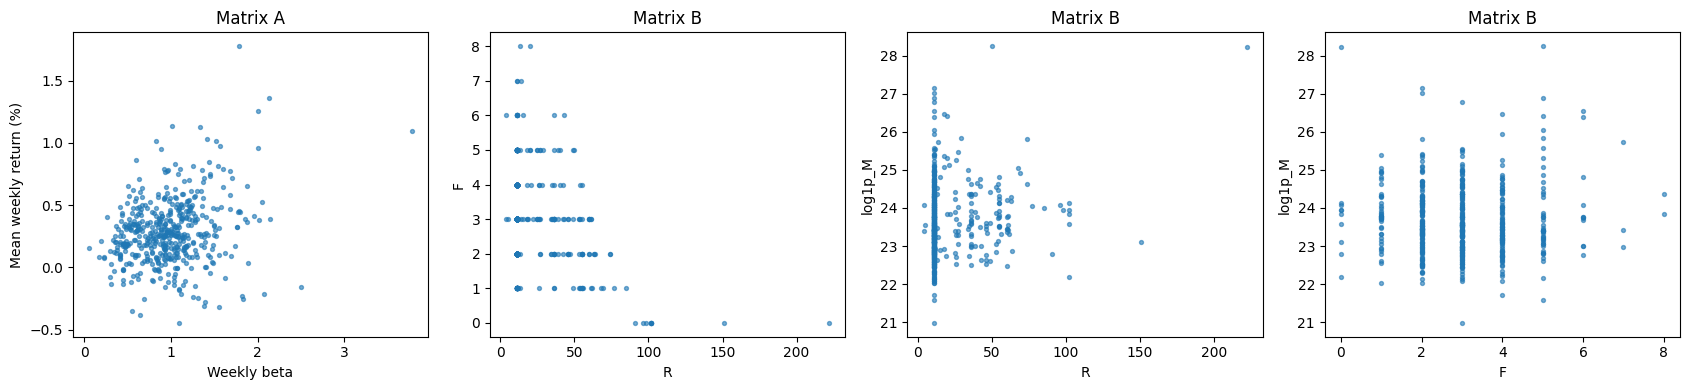

In [40]:
ig, ax = plt.subplots(2, 2, figsize=(10, 7))
ax[0, 0].hist(raw["M"] / 1e9, bins=40);      ax[0, 0].set_xlabel("Monetary (USD billions)")
ax[0, 1].hist(raw["log1p_M"], bins=40);      ax[0, 1].set_xlabel("log1p(Monetary)")
ax[1, 0].hist(raw["R"], bins=40);            ax[1, 0].set_xlabel("Recency (calendar days)"); ax[1, 0].set_yscale("log")
ax[1, 1].hist(raw["log1p_R"], bins=40);      ax[1, 1].set_xlabel("log1p(Recency)"); ax[1, 1].set_yscale("log")
for a in ax.ravel():
    a.set_ylabel("Number of shares")
fig.suptitle(f"Effect of log1p on skewed features (n={len(common)})")
plt.tight_layout()
plt.savefig("outputs/figures/fig_transform_effect.png", dpi=200)
plt.show()

fig, ax = plt.subplots(1, 4, figsize=(17, 4))
ax[0].scatter(X_rr_raw["weekly_beta"], X_rr_raw["mean_weekly_return"] * 100, s=8, alpha=0.6)
ax[0].set_xlabel("Weekly beta"); ax[0].set_ylabel("Mean weekly return (%)"); ax[0].set_title("Matrix A")
pairs = [("R", "F"), ("R", "log1p_M"), ("F", "log1p_M")]
for a, (x, y) in zip(ax[1:], pairs):
    xc = x if x in X_act_raw else "log1p_R"
    a.scatter(X_act_raw[xc], X_act_raw[y], s=8, alpha=0.6)
    a.set_xlabel(xc); a.set_ylabel(y); a.set_title("Matrix B")
plt.tight_layout()
plt.savefig("outputs/figures/fig_matrix_scatter.png", dpi=200)
plt.show()

In [41]:
meta = {
    "n_shares_common_set": int(len(common)),
    "matrix_A_features": list(X_rr.columns),
    "matrix_B_features": list(X_act.columns),
    "log1p_applied_to": ["M"] + (["R"] if LOG_R else []),
    "scaler": "sklearn StandardScaler (mean 0, population std 1), fitted separately per matrix",
    "matrix_A_means": {k: float(v) for k, v in zip(X_rr.columns, sc_rr.mean_)},
    "matrix_A_stds": {k: float(v) for k, v in zip(X_rr.columns, sc_rr.scale_)},
    "matrix_B_means": {k: float(v) for k, v in zip(X_act.columns, sc_act.mean_)},
    "matrix_B_stds": {k: float(v) for k, v in zip(X_act.columns, sc_act.scale_)},
    "outliers": "retained (real observations); influence quantified in feature_diagnostics.csv",
    "calculation_version": "v1",
}
json.dump(meta, open("outputs/feature_preparation_metadata.json", "w"), indent=2)
print(json.dumps(meta, indent=2))

{
  "n_shares_common_set": 486,
  "matrix_A_features": [
    "mean_weekly_return",
    "weekly_beta"
  ],
  "matrix_B_features": [
    "R",
    "F",
    "log1p_M"
  ],
  "log1p_applied_to": [
    "M"
  ],
  "scaler": "sklearn StandardScaler (mean 0, population std 1), fitted separately per matrix",
  "matrix_A_means": {
    "mean_weekly_return": 0.002857173085642157,
    "weekly_beta": 0.9736952722623052
  },
  "matrix_A_stds": {
    "mean_weekly_return": 0.0026488793066468726,
    "weekly_beta": 0.4069196314408604
  },
  "matrix_B_means": {
    "R": 20.40740740740741,
    "F": 2.9897119341563787,
    "log1p_M": 23.68212456183186
  },
  "matrix_B_stds": {
    "R": 21.32046937255646,
    "F": 1.3294299032424965,
    "log1p_M": 0.9412334803637373
  },
  "outliers": "retained (real observations); influence quantified in feature_diagnostics.csv",
  "calculation_version": "v1"
}
